**Step 1: Import Libraries**

In [25]:
# Data handling
import numpy as np
import pandas as pd

# data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# splitting
from sklearn.model_selection import train_test_split

# preprocessing
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# deep learning core
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, ReLU, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

#metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import  r2_score, root_mean_squared_error

**Step 2: Load Dataset**

In [6]:
df = pd.read_csv(r"D:\Deep Learning\Projects\ANN\2_House_ANN_Project\Data\house_clean.csv")
df.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price,Area_per_Bedroom,Bathroom_per_Bedroom,LuxuryScore,Accessibility
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05,226.666667,0.333333,1,2
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06,854.400000,0.400000,2,3
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06,3592.000000,4.000000,3,2
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05,193.200000,0.400000,1,2
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06,1231.500000,0.750000,0,3


**Step 3: Features & tragets**

In [8]:
X = df.drop(columns=['income_level','price'])
y = df['price']

**Step 4: Train-test-split**

In [9]:
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Step 5: Preprocessing pipeline**

**Encode target**

No need

In [16]:
df[['area', 'bedrooms', 'bathrooms', 'floors', 'age', 'distance', 'garage',
       'parking', 'garden', 'security', 'school_nearby', 'hospital_nearby',
       'shopping_mall_nearby', 'public_transport', 'crime_rate',
       'population_density', 'location','Area_per_Bedroom', 'Bathroom_per_Bedroom', 'LuxuryScore',
       'Accessibility']]

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,Area_per_Bedroom,Bathroom_per_Bedroom,LuxuryScore,Accessibility
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,226.666667,0.333333,1,2
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,854.400000,0.400000,2,3
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,3592.000000,4.000000,3,2
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,193.200000,0.400000,1,2
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,1231.500000,0.750000,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,733,1,4,1,23,23,0,0,1,0,0,1,1,1,1.699633,2188,premium,733.000000,4.000000,1,3
49996,3420,4,1,3,9,13,1,1,1,0,0,0,1,1,9.451960,7273,low,855.000000,0.250000,3,2
49997,2218,3,1,2,3,6,0,1,1,0,1,0,0,1,8.659219,9856,medium,739.333333,0.333333,2,2
49998,992,2,4,3,26,20,1,0,0,0,0,0,1,0,6.343849,2858,premium,496.000000,2.000000,1,1


**Encode Features**

In [17]:
num_cols = ['area', 'bedrooms', 'bathrooms', 'floors', 'age', 'distance', 'garage',
       'parking', 'garden', 'security', 'school_nearby', 'hospital_nearby',
       'shopping_mall_nearby', 'public_transport', 'crime_rate',
       'population_density', 'Area_per_Bedroom', 'Bathroom_per_Bedroom', 'LuxuryScore',
       'Accessibility']

cat_cols = ['location']

num_transformer = Pipeline([
    ('imp',SimpleImputer(strategy='median')),
    ('scr',StandardScaler())
])

cat_transformer = Pipeline([
    ('imp',SimpleImputer(strategy='most_frequent')),
    # 'sparse_output=False' --> ensures it returns a normal numpy array instead of a matrix
    # 'drop='first'' --> removes one column per feature to prevent the dummy variable trap
    ('ohe',OneHotEncoder(sparse_output=False, drop='first'))
])

processor = ColumnTransformer([
    ('num_processing',num_transformer, num_cols),
    ('cat_processing',cat_transformer, cat_cols)
], remainder='passthrough')

X_train_processed = processor.fit_transform(X_train)
X_test_processed = processor.transform(X_test)

**Step 6: Build ANN Model**

In [20]:
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1)        #  no softmax/sigmoid activation

])

**Step 7: Compile model**

In [22]:
model.compile(
    optimizer="adam",
    loss="mse",         # Mean Squared Error for regression
    metrics=["mae"]     # Mean Absolute Error (average price error in dollars)
)

**Step 8: Model summary**

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,225 (16.50 KB)

 Non-trainable params: 0 (0.00 B)

**Step 9: Train model**

In [40]:
history = model.fit(X_train_processed, y_train,
        validation_split=0.2,
        batch_size=100, 
        epochs=50, 
        callbacks=EarlyStopping()
)

Epoch 1/50


320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 896538048.0000 - mae: 24335.6914 - val_loss: 921641024.0000 - val_mae: 24742.0703
Epoch 2/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 892321728.0000 - mae: 24276.2969 - val_loss: 911844416.0000 - val_mae: 24633.4629
Epoch 3/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 889643392.0000 - mae: 24258.0586 - val_loss: 905726784.0000 - val_mae: 24591.5742
Epoch 4/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 884160704.0000 - mae: 24183.2461 - val_loss: 907447168.0000 - val_mae: 24558.9180


**Step 10: prediction**

In [41]:
y_pred_prices = model.predict(X_test_processed)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 941us/step


**Step 11: Evaluate model**

In [42]:
r2 = r2_score(y_test, y_pred_prices)
rmse = root_mean_squared_error(y_test, y_pred_prices)

print("=== Keras Regression Performance ===")
print(f"R2 Score (Accuracy Model Fit): {round(r2*100,3)} %")
print(f"Average Price Error (RMSE):    {rmse:.2f}")

=== Keras Regression Performance ===
R2 Score (Accuracy Model Fit): 99.581 %
Average Price Error (RMSE):    29724.82


**Step 12: Classification report**

Regression doesn't have classes, so there's no classification report.

**Step 13: confusion matrix**

Confusion matrices are only for classification.

**Step 14: Training Curve**

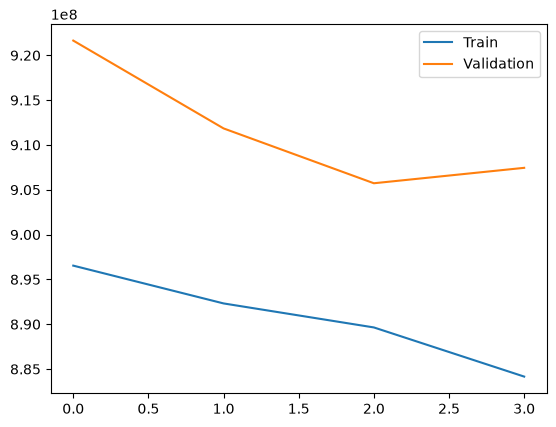

In [43]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.show()

**Ste 15: Save model**

In [44]:
model.save("../Models/price_model.keras")
print("Model Saved successfully...!")

Model Saved successfully...!
